# 03 · Training and evaluation

Models, each trained on four label granularities:

| label set | classes | source |
|---|---|---|
| `group` | 8 | arXiv top-level groups |
| `archive` | ~20 | arXiv archives |
| `discovered` | k from notebook 02 | arXiv categories merged by abstract similarity |
| `fine` | ~140 | arXiv primary categories |

* **Baseline:** TF-IDF (1–2-grams) + logistic regression.
* **Transformer:** `bert-base-uncased` fine-tuned with Hugging Face `Trainer` — max length 256,
  lr 2e-5, effective batch 32, 3 epochs, 10% warmup, class-weighted cross-entropy, fp16,
  early stopping on validation macro-F1.

Evaluation is on the **validation** split; the test split is reserved for the final model in notebook 04.
Runs on a Kaggle GPU (T4 ×2, ~2 h).

In [1]:
import glob
import shutil
import sys
from pathlib import Path


def add_src_to_path():
    hits = glob.glob("/kaggle/input/**/taxonomy.py", recursive=True)
    if hits:
        pkg = Path("/tmp/pkg/src")
        shutil.copytree(Path(hits[0]).parent, pkg, dirs_exist_ok=True)
        sys.path.insert(0, str(pkg.parent))
    else:
        sys.path.insert(0, str(Path.cwd().parent))


add_src_to_path()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src import evaluate, taxonomy, viz
from src.train import LabelSpace, TrainConfig, tfidf_logreg, train_transformer
from src.utils import DATA_DIR, FIG_DIR, RESULTS_DIR, ensure_dirs, find_input, load_json, save_json, set_seed

set_seed()
ensure_dirs()
viz.apply_style()
print("GPUs:", torch.cuda.device_count(), [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
assert torch.cuda.is_available(), "No GPU: set Accelerator to GPU (needs a phone-verified Kaggle account)"

train = pd.read_parquet(find_input("train.parquet"))
val = pd.read_parquet(find_input("val.parquet"))
best_k = load_json(find_input("best_k.json"))
K = best_k["best_k"]
discovered = taxonomy.discovered_label(best_k["mapping"])
for df in (train, val):
    df["discovered"] = df["fine"].map(discovered)

LEVELS = ["group", "archive", "discovered", "fine"]
spaces = {lvl: LabelSpace(train[lvl]) for lvl in LEVELS}
print({lvl: len(s) for lvl, s in spaces.items()}, "| discovered k =", K)

GPUs: 2 ['Tesla T4', 'Tesla T4']


{'group': 8, 'archive': 20, 'discovered': 12, 'fine': 148} | discovered k = 12


## Token lengths: is 256 enough?

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (524 > 512). Running this sequence through the model will result in indexing errors


median 211.0 p95 377.0 share<=256 0.6783


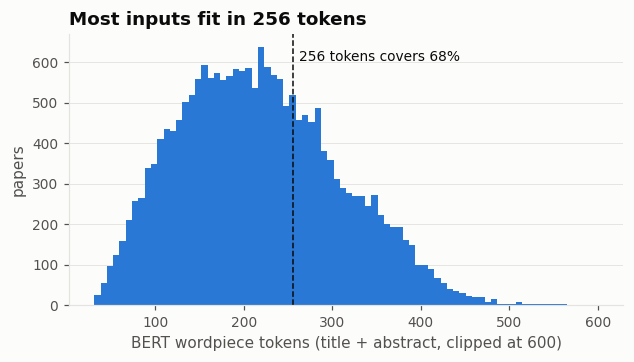

In [2]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("bert-base-uncased")
lengths = np.array([len(x) for x in tok(train["text"].sample(20000, random_state=0).tolist())["input_ids"]])
share_256 = float((lengths <= 256).mean())
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(np.clip(lengths, 0, 600), bins=80, color=viz.ACCENT)
ax.axvline(256, color=viz.TEXT, lw=1, ls="--")
ax.text(262, ax.get_ylim()[1] * 0.9, f"256 tokens covers {share_256:.0%}", fontsize=9)
ax.set_xlabel("BERT wordpiece tokens (title + abstract, clipped at 600)")
ax.set_ylabel("papers")
ax.set_title("Most inputs fit in 256 tokens")
ax.grid(axis="x", visible=False)
viz.save(fig, "fig12_token_lengths", FIG_DIR)
print("median", np.median(lengths), "p95", np.percentile(lengths, 95), "share<=256", share_256)

## Smoke test
A few steps on a tiny slice, so a bug fails in one minute rather than after an hour.

In [3]:
small = train.sample(256, random_state=0)
_ = train_transformer(TrainConfig(epochs=1, max_length=64), small["text"], spaces["group"].encode(small["group"]),
                      {"val": (small["text"][:64], spaces["group"].encode(small["group"][:64]))},
                      len(spaces["group"]), "/tmp/ckpt/smoke")
print("smoke test ok")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/256 [00:00<?, ? examples/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

[transformers] There were unexpected keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.beta', 'bert.embeddings.LayerNorm.gamma', 'bert.encoder.layer.0.attention.output.LayerNorm.beta', 'bert.encoder.layer.0.attention.output.LayerNorm.gamma', 'bert.encoder.layer.0.output.LayerNorm.beta', 'bert.encoder.layer.0.output.LayerNorm.gamma', 'bert.encoder.layer.1.attention.output.LayerNorm.beta', 'bert.encoder.layer.1.attention.output.LayerNorm.gamma', 'bert.encoder.layer.1.output.LayerNorm.beta', 'bert.encoder.layer.1.output.LayerNorm.gamma', 'bert.encoder.layer.2.attention.output.LayerNorm.beta', 'bert.encoder.layer.2.attention.output.LayerNorm.gamma', 'bert.encoder.layer.2.output.LayerNorm.beta', 'bert.encoder.layer.2.output.LayerNorm.gamma', 'bert.encoder.layer.3.attention.output.LayerNorm.beta', 'bert.encoder.layer.3.attention.output.LayerNorm.gamma', 'bert.encoder.layer.3.output.LayerNorm.beta', 'bert.encoder.layer.3.output.LayerNorm.gamma', 'bert.encoder.layer.4.attention.

{'train_runtime': '5.75', 'train_samples_per_second': '44.52', 'train_steps_per_second': '1.391', 'train_loss': '2.087', 'epoch': '1'}


smoke test ok


## Baseline: TF-IDF + logistic regression

In [4]:
rows, all_metrics = [], {}
for lvl in LEVELS:
    sp = spaces[lvl]
    scores, secs = tfidf_logreg(train["text"], sp.encode(train[lvl]), {"val": val["text"]})
    m = evaluate.metrics(sp.encode(val[lvl]), scores["val"], sp.names)
    all_metrics[f"tfidf_logreg/{lvl}"] = m
    rows.append({"model": "TF-IDF + LogReg", "label_set": lvl, "n_classes": len(sp), "train_seconds": secs,
                 **{k: v for k, v in m.items() if k != "per_class"}})
    print(rows[-1])

{'model': 'TF-IDF + LogReg', 'label_set': 'group', 'n_classes': 8, 'train_seconds': 79.76986312866211, 'accuracy': 0.8518918918918919, 'macro_f1': 0.7787862788665663, 'micro_f1': 0.8518918918918919, 'weighted_f1': 0.854709627132686, 'top3_accuracy': 0.9827027027027027}


{'model': 'TF-IDF + LogReg', 'label_set': 'archive', 'n_classes': 20, 'train_seconds': 159.65033411979675, 'accuracy': 0.7835135135135135, 'macro_f1': 0.7035934228899503, 'micro_f1': 0.7835135135135135, 'weighted_f1': 0.786086267945537, 'top3_accuracy': 0.9643243243243244}


{'model': 'TF-IDF + LogReg', 'label_set': 'discovered', 'n_classes': 12, 'train_seconds': 119.23017120361328, 'accuracy': 0.7893243243243243, 'macro_f1': 0.7950679505050225, 'micro_f1': 0.7893243243243243, 'weighted_f1': 0.7896974475651283, 'top3_accuracy': 0.9605405405405405}


{'model': 'TF-IDF + LogReg', 'label_set': 'fine', 'n_classes': 148, 'train_seconds': 459.70670342445374, 'accuracy': 0.5745945945945946, 'macro_f1': 0.5698603822300161, 'micro_f1': 0.5745945945945946, 'weighted_f1': 0.5698603822300162, 'top3_accuracy': 0.8193243243243243}


## BERT fine-tuning

In [5]:
cfg = TrainConfig()  # defaults listed in the header
bert_scores, bert_info = {}, {}
for lvl in LEVELS:
    sp = spaces[lvl]
    scores, info = train_transformer(cfg, train["text"], sp.encode(train[lvl]),
                                     {"val": (val["text"], sp.encode(val[lvl]))}, len(sp), f"/tmp/ckpt/bert_{lvl}")
    m = evaluate.metrics(sp.encode(val[lvl]), scores["val"], sp.names)
    all_metrics[f"bert/{lvl}"] = m
    bert_scores[lvl], bert_info[lvl] = scores["val"], info
    np.save(DATA_DIR / f"val_logits_bert_{lvl}.npy", scores["val"])
    rows.append({"model": "BERT-base", "label_set": lvl, "n_classes": len(sp), "train_seconds": info["train_seconds"],
                 **{k: v for k, v in m.items() if k != "per_class"}})
    print(rows[-1])
    torch.cuda.empty_cache()

results = pd.DataFrame(rows)
results.to_csv(RESULTS_DIR / "model_results.csv", index=False)
save_json({"metrics": all_metrics, "bert_training": bert_info, "discovered_k": K}, RESULTS_DIR / "model_results_detail.json")
results[["model", "label_set", "n_classes", "accuracy", "macro_f1", "micro_f1", "top3_accuracy", "train_seconds"]].round(4)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/59200 [00:00<?, ? examples/s]

Map:   0%|          | 0/7400 [00:00<?, ? examples/s]

{'loss': '2.072', 'grad_norm': '8.027', 'learning_rate': '3.568e-06', 'epoch': '0.05405'}


...

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

[transformers] There were unexpected keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.beta', 'bert.embeddings.LayerNorm.gamma', 'bert.encoder.layer.0.attention.output.LayerNorm.beta', 'bert.encoder.layer.0.attention.output.LayerNorm.gamma', 'bert.encoder.layer.0.output.LayerNorm.beta', 'bert.encoder.layer.0.output.LayerNorm.gamma', 'bert.encoder.layer.1.attention.output.LayerNorm.beta', 'bert.encoder.layer.1.attention.output.LayerNorm.gamma', 'bert.encoder.layer.1.output.LayerNorm.beta', 'bert.encoder.layer.1.output.LayerNorm.gamma', 'bert.encoder.layer.2.attention.output.LayerNorm.beta', 'bert.encoder.layer.2.attention.output.LayerNorm.gamma', 'bert.encoder.layer.2.output.LayerNorm.beta', 'bert.encoder.layer.2.output.LayerNorm.gamma', 'bert.encoder.layer.3.attention.output.LayerNorm.beta', 'bert.encoder.layer.3.attention.output.LayerNorm.gamma', 'bert.encoder.layer.3.output.LayerNorm.beta', 'bert.encoder.layer.3.output.LayerNorm.gamma', 'bert.encoder.layer.4.attention.

{'train_runtime': '4946', 'train_samples_per_second': '35.91', 'train_steps_per_second': '1.122', 'train_loss': '2.477', 'epoch': '3'}


{'model': 'BERT-base', 'label_set': 'fine', 'n_classes': 148, 'train_seconds': 4946.713790893555, 'accuracy': 0.525, 'macro_f1': 0.505743233980588, 'micro_f1': 0.525, 'weighted_f1': 0.5057432339805878, 'top3_accuracy': 0.7660810810810811}


,model,label_set,n_classes,accuracy,macro_f1,micro_f1,top3_accuracy,train_seconds
0,TF-IDF + LogReg,group,8,0.8519,0.7788,0.8519,0.9827,79.7699
1,TF-IDF + LogReg,archive,20,0.7835,0.7036,0.7835,0.9643,159.6503
2,TF-IDF + LogReg,discovered,12,0.7893,0.7951,0.7893,0.9605,119.2302
3,TF-IDF + LogReg,fine,148,0.5746,0.5699,0.5746,0.8193,459.7067
4,BERT-base,group,8,0.8508,0.7888,0.8508,0.9865,4944.6183
5,BERT-base,archive,20,0.7564,0.6686,0.7564,0.9557,4947.2210
6,BERT-base,discovered,12,0.7947,0.8005,0.7947,0.9646,4946.2478
7,BERT-base,fine,148,0.5250,0.5057,0.5250,0.7661,4946.7138


## Macro-F1 against the number of classes

PosixPath('/kaggle/working/reports/figures/fig13_f1_vs_classes.png')

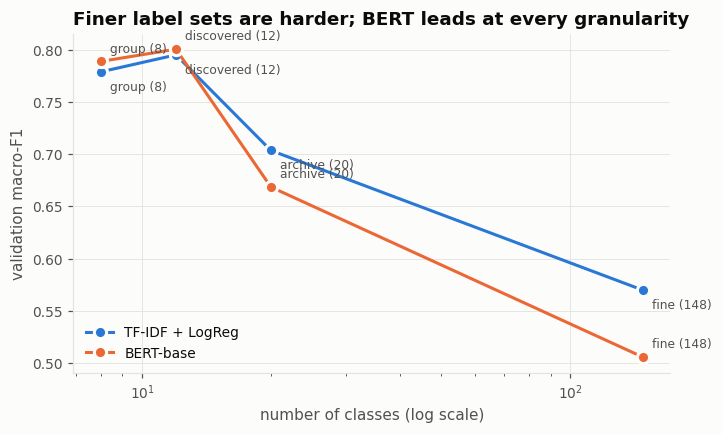

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for (model, d), color in zip(results.groupby("model", sort=False), viz.SERIES):
    d = d.sort_values("n_classes")
    ax.plot(d["n_classes"], d["macro_f1"], "-o", color=color, label=model, mec=viz.SURFACE, mew=2, ms=8)
    for _, r in d.iterrows():
        ax.annotate(f"{r['label_set']} ({r['n_classes']})", (r["n_classes"], r["macro_f1"]),
                    textcoords="offset points", xytext=(6, 6 if model == "BERT-base" else -12),
                    fontsize=8, color=viz.TEXT_2)
ax.set_xscale("log")
ax.set_xlabel("number of classes (log scale)")
ax.set_ylabel("validation macro-F1")
ax.set_title("Finer label sets are harder; BERT leads at every granularity")
ax.legend(loc="lower left")
viz.save(fig, "fig13_f1_vs_classes", FIG_DIR)

## Confusion matrices (BERT)

PosixPath('/kaggle/working/reports/figures/fig14_confusion.png')

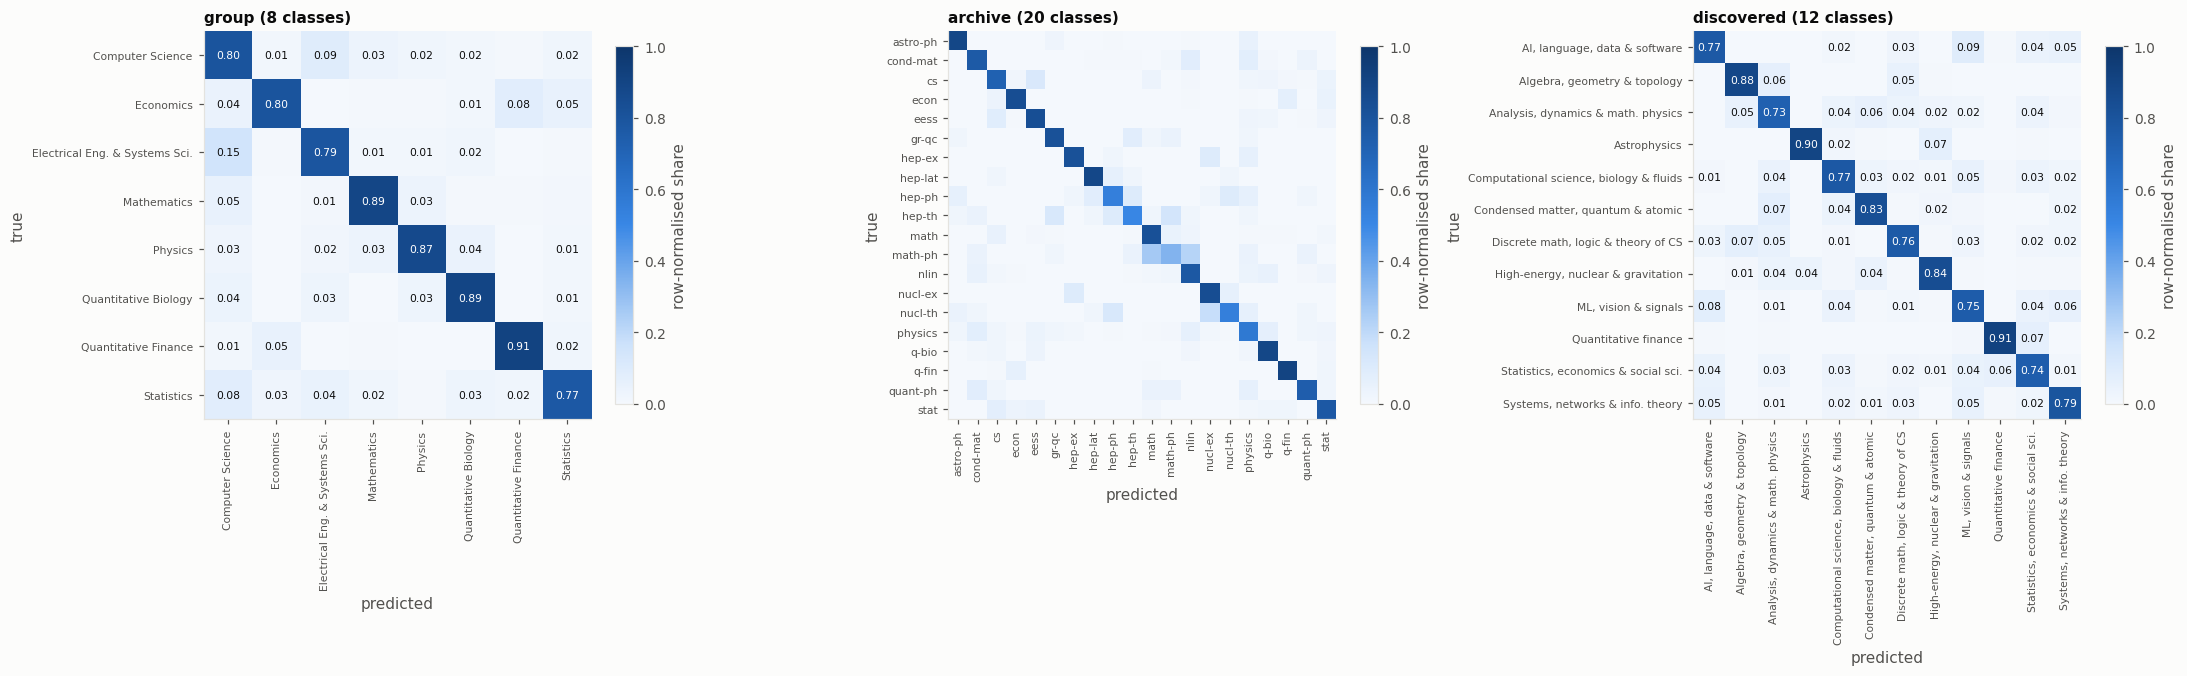

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
for ax, lvl in zip(axes, ["group", "archive", "discovered"]):
    sp = spaces[lvl]
    evaluate.plot_confusion(sp.encode(val[lvl]), bert_scores[lvl].argmax(1), sp.names,
                            f"{lvl} ({len(sp)} classes)", ax=ax)
fig.tight_layout()
viz.save(fig, "fig14_confusion", FIG_DIR)

In [8]:
# Do the model's mistakes follow arXiv cross-listing? Compare the most-confused fine pairs.
sp = spaces["fine"]
confused = evaluate.most_confused(sp.encode(val["fine"]), bert_scores["fine"].argmax(1), sp.names, n=15)
confused_df = pd.DataFrame(confused, columns=["true", "predicted", "count"])
confused_df.to_csv(RESULTS_DIR / "most_confused_fine.csv", index=False)
confused_df

,true,predicted,count
0,cs.SD,eess.AS,25
1,q-fin.MF,q-fin.PR,23
2,eess.SP,cs.IT,14
3,cs.DM,math.CO,14
4,q-fin.CP,q-fin.ST,14
5,q-fin.CP,q-fin.PR,13
6,cond-mat.other,cond-mat.quant-gas,13
7,math.RA,math.AC,13
8,eess.AS,cs.SD,12
9,math.GM,math.NT,11


In [9]:
# Weakest and strongest fine categories.
pc = pd.DataFrame(all_metrics["bert/fine"]["per_class"]).T.drop(["accuracy", "macro avg", "weighted avg"], errors="ignore")
pc = pc.sort_values("f1-score")
pd.concat([pc.head(8), pc.tail(8)])[["precision", "recall", "f1-score", "support"]].round(3)

,precision,recall,f1-score,support
cs.OH,0.200,0.02,0.036,50.0
cond-mat.other,0.222,0.04,0.068,50.0
q-fin.CP,0.400,0.04,0.073,50.0
math.GM,0.375,0.06,0.103,50.0
physics.bio-ph,0.267,0.08,0.123,50.0
math-ph,0.294,0.10,0.149,50.0
cs.AI,0.357,0.10,0.156,50.0
q-fin.MF,0.389,0.14,0.206,50.0
cs.IR,0.684,0.78,0.729,50.0
cs.SE,0.678,0.80,0.734,50.0
